In [1]:
from pathlib import Path
BASE = Path("/home/lka/HYBRID_SARIMA")
print(BASE.exists(), BASE)

#Import the file to read it
import pandas as pd
disocupati_trimestral = pd.read_csv(BASE / 'data.csv', 
                       index_col='Period', 
                       parse_dates=True)
print(disocupati_trimestral)

True /home/lka/HYBRID_SARIMA
             15-34 M    15-34 F   35-49 M   35-49 F   50-74 M   50-74 F  \
Period                                                                    
2004-Q1    11.720628  17.198032  4.283283  8.776062  4.004764  5.376203   
2004-Q2    11.410664  16.187372  3.654493  7.196378  3.636536  4.515018   
2004-Q3    10.041510  15.682014  3.520125  6.945425  3.394804  3.976243   
2004-Q4    11.918557  17.227696  4.020448  7.582207  3.604743  3.583677   
2005-Q1    12.334781  16.852636  4.316241  7.577546  3.440298  4.204936   
...              ...        ...       ...       ...       ...       ...   
2025-Q2    11.341464  13.635416  5.106017  7.025122  3.776334  3.889283   
2025-Q3     9.628072  11.355385  4.656108  6.239399  3.108541  3.482718   
2025-Q4    10.903735  10.928362  3.989899  5.704370  3.250742  3.129547   
2026-Q1     9.534584  10.900056  4.316380  5.611548  2.984988  3.392216   
2026-Q2    10.244865  11.855438  5.044973  6.388627  3.268385  3.460483

/tmp/ipykernel_57922/3099411105.py:7: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  disocupati_trimestral = pd.read_csv(BASE / 'data.csv',


In [2]:
#Dividir el dataset en training, validation y test
series = [
    '15-34 M', '15-34 F',
    '35-49 M', '35-49 F',
    '50-74 M', '50-74 F',
    'Global_Rate'
]

# Ordenar cronológicamente
df = disocupati_trimestral.sort_index()

# División 70% Train, 15% Validation, 15% Test
n = len(df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train = df[series].iloc[:train_end].copy()
val = df[series].iloc[train_end:val_end].copy()
test = df[series].iloc[val_end:].copy()

# Mostrar resultados para cada serie
#for serie in series:
#    print(f"\nSerie: {serie}")
#    print(f"Train: {len(train[serie])} observaciones")
#    print(f"Validation: {len(val[serie])} observaciones")
#    print(f"Test: {len(test[serie])} observaciones")

print(train)
print(val)
print(test)


             15-34 M    15-34 F   35-49 M    35-49 F   50-74 M   50-74 F  \
Period                                                                     
2004-Q1    11.720628  17.198032  4.283283   8.776062  4.004764  5.376203   
2004-Q2    11.410664  16.187372  3.654493   7.196378  3.636536  4.515018   
2004-Q3    10.041510  15.682014  3.520125   6.945425  3.394804  3.976243   
2004-Q4    11.918557  17.227696  4.020448   7.582207  3.604743  3.583677   
2005-Q1    12.334781  16.852636  4.316241   7.577546  3.440298  4.204936   
...              ...        ...       ...        ...       ...       ...   
2018-Q2    17.908050  21.321705  7.759217  10.435680  6.683032  6.283515   
2018-Q3    16.802144  19.343542  6.191831   9.120602  5.538136  5.299045   
2018-Q4    19.322895  22.132355  7.396393  10.673055  6.327076  6.189145   
2019-Q1    19.163606  21.713279  8.111591  11.250865  6.697788  6.034775   
2019-Q2    17.128382  19.347371  7.161324   9.818228  5.738406  5.356958   

           

In [4]:
import warnings
warnings.filterwarnings("ignore")
import itertools
import warnings
import numpy as np
import pandas as pd
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.stattools import jarque_bera
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [ ]:
pdq=list(itertools.product(range(3),repeat=3))
seasonal_pdq=[(P,D,Q,4) for P,D,Q in pdq]
sarima_models,results={},[]
for col in train.columns:
    y_train=train[col].dropna().reset_index(drop=True) # aqui se asegura que los índices se reinicien después de eliminar los valores nulos
    y_val=val[col].dropna().reset_index(drop=True) # aqui se asegura que los índices se reinicien después de eliminar los valores nulos
    candidatos=[]
    for order in pdq:
        for seasonal_order in seasonal_pdq:
            try:
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")
                    model=SARIMAX(y_train,order=order,seasonal_order=seasonal_order,enforce_stationarity=True,enforce_invertibility=True)
                    fitted_model=model.fit(disp=False)
                if fitted_model.mle_retvals.get("converged",False) and np.isfinite(fitted_model.bic): # aqui se seleccionan solo los modelos que convergieron y tienen BIC finito
                    candidatos.append((fitted_model.bic,fitted_model)) 
            except Exception:
                continue
    sarima_models[col]=[]
    for bic,model in sorted(candidatos,key=lambda x:x[0]):
        if len(sarima_models[col])==5:
            break
        try:
            pred=np.asarray(model.forecast(steps=len(y_val)))
            if not np.all(np.isfinite(pred)):
                continue
            real=y_val.to_numpy()
            values=y_train.to_numpy()
            mae=mean_absolute_error(real,pred)
            mse=mean_squared_error(real,pred)
            mask=real!=0
            mape=np.mean(np.abs((real[mask]-pred[mask])/real[mask]))*100 if mask.any() else np.nan
            scale=np.mean(np.abs(values[4:]-values[:-4])) if len(values)>4 else np.nan
            lb_test=acorr_ljungbox(model.resid,return_df=True)
            lb_pvalue=lb_test["lb_pvalue"].values[-1] if not lb_test.empty else np.nan
            jb_test=jarque_bera(model.resid)
            jb_pvalue=jb_test[1] if jb_test is not None else np.nan
            hetero_test=het_arch(model.resid)
            hetero_pvalue=hetero_test[1] if hetero_test is not None else np.nan
            results.append({
                "Serie":col,"Rank":len(sarima_models[col]),
                "Order":model.model.order,"Seasonal_Order":model.model.seasonal_order,
                "AIC":model.aic,"BIC":bic,"MAE":mae,
                "MSE":mse,"RMSE":np.sqrt(mse),"MAPE":mape,
                "MASE":mae/scale if np.isfinite(scale) and scale>0 else np.nan,
                "R2":r2_score(real,pred) if len(real)>1 else np.nan,
                "Ljung-Box (p-value)":lb_pvalue,
                "Jarque-Bera (p-value)":jb_pvalue,
                "Heteroscedasticity (p-value)":hetero_pvalue
            })
            sarima_models[col].append(model)
        except (ValueError,FloatingPointError,OverflowError):
            continue
    print(f"{col} (ok)")

top5_sarima=pd.DataFrame(results).round(4)
(BASE/"results").mkdir(parents=True,exist_ok=True)
top5_sarima.to_csv(BASE/"results"/"top5_sarima.csv",index=False)

#Para ver los resultados ver el archivo CSV generado en la carpeta "results"


15-34 M (ok)
15-34 F (ok)
35-49 M (ok)
35-49 F (ok)
50-74 M (ok)
50-74 F (ok)
Global_Rate (ok)


,Serie,Rank,Order,Seasonal_Order,AIC,BIC,MAE,MSE,RMSE,MAPE,MASE,R2,Ljung-Box (p-value),Jarque-Bera (p-value),Heteroscedasticity (p-value)
0,15-34 M,1,"(0, 1, 0)","(0, 1, 1, 4)",160.1023,164.1884,1.8727,4.5042,2.1223,12.7907,1.1556,0.1351,0.6716,0.0,0.4981
1,15-34 M,2,"(0, 1, 0)","(1, 1, 1, 4)",160.9988,167.1280,2.7997,11.6226,3.4092,20.0201,1.7276,-1.2317,0.6071,0.0,0.6398
2,15-34 M,3,"(0, 1, 0)","(0, 1, 2, 4)",161.4346,167.5637,2.6092,9.9653,3.1568,18.5898,1.6101,-0.9135,0.6401,0.0,0.5851
3,15-34 M,4,"(1, 1, 0)","(0, 1, 1, 4)",161.9804,168.1095,1.9433,4.9507,2.2250,13.3797,1.1991,0.0494,0.6598,0.0,0.4091
4,15-34 M,5,"(0, 1, 1)","(0, 1, 1, 4)",162.0036,168.1327,1.9309,4.8684,2.2064,13.2767,1.1915,0.0652,0.6622,0.0,0.4259
5,15-34 F,1,"(0, 1, 0)","(0, 1, 1, 4)",168.4573,172.5434,1.5209,3.4749,1.8641,8.0265,0.9468,0.0227,0.4698,0.0,0.9471
6,15-34 F,2,"(0, 1, 0)","(1, 1, 1, 4)",169.6670,175.7962,1.9045,4.7915,2.1890,10.5697,1.1856,-0.3476,0.4315,0.0,0.9053
7,15-34 F,3,"(0, 1, 0)","(0, 1, 2, 4)",169.7404,175.8695,1.8355,4.3979,2.0971,10.1121,1.1427,-0.2369,0.4381,0.0,0.9183
8,15-34 F,4,"(0, 1, 1)","(0, 1, 1, 4)",170.2446,176.3738,1.4982,3.5139,1.8745,7.8642,0.9327,0.0117,0.4763,0.0,0.9516
9,15-34 F,5,"(1, 1, 0)","(0, 1, 1, 4)",170.2852,176.4144,1.5010,3.5063,1.8725,7.8849,0.9345,0.0138,0.4750,0.0,0.9500


In [ ]:
#A partir de los resultados del grid search, se seleccionaron los mejores modelos SARIMA para cada serie
#Serie         Order      Seasonal_Order
#15-34 M       (0,1,0)    (0,1,1,4)
#15-34 F       (0,1,0)    (0,1,1,4)
#35-49 M       (0,1,0)    (1,1,2,4)
#35-49 F       (0,1,0)    (0,1,1,4)
#50-74 M       (2,1,1)    (0,1,1,4)
#50-74 F       (2,1,0)    (0,1,1,4)
#Global Rate   (0,1,0)    (0,1,1,4)

In [14]:
# Ahora se va entrenar el modelo SARIMA para cada serie con los mejores parámetros seleccionados train + val y se evaluará en el conjunto de prueba
import warnings
warnings.filterwarnings("ignore")
sarima_best_params = {
    "15-34 M": {"order": (0,1,0), "seasonal_order": (0,1,1,4)},
    "15-34 F": {"order": (0,1,0), "seasonal_order": (0,1,1,4)},
    "35-49 M": {"order": (0,1,0), "seasonal_order": (1,1,2,4)},
    "35-49 F": {"order": (0,1,0), "seasonal_order": (0,1,1,4)},
    "50-74 M": {"order": (2,1,1), "seasonal_order": (0,1,1,4)},
    "50-74 F": {"order": (2,1,0), "seasonal_order": (0,1,1,4)},
    "Global_Rate": {"order": (0,1,0), "seasonal_order": (0,1,1,4)}
}
sarima_results = {}
sarima_predictions = {}
for col, params in sarima_best_params.items():
    y_train_val = pd.concat([train[col], val[col]])
    y_test = test[col]
    model = SARIMAX(y_train_val, order=params["order"], seasonal_order=params["seasonal_order"], enforce_stationarity=True, enforce_invertibility=True)
    fitted_model = model.fit(disp=False)
    pred = np.asarray(fitted_model.forecast(steps=len(y_test)))
    sarima_predictions[col] = pred
    real = y_test.to_numpy()
    mse =mean_squared_error(real, pred)
    rmse = np.sqrt(mean_squared_error(real, pred))
    mae = mean_absolute_error(real, pred)
    mask = real != 0
    mape = np.mean(np.abs((real[mask] - pred[mask]) / real[mask])) * 100 if mask.any() else np.nan
    r2 = r2_score(real, pred) if len(real) > 1 else np.nan
    sarima_results[col] = {
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae,
        "MAPE": mape,
        "R2": r2,
        "Order": fitted_model.model.order,
        "Seasonal_Order": fitted_model.model.seasonal_order
    }
    print(f"{col} (ok)")

sarima_results_df = pd.DataFrame(sarima_results).T.round(4)
(BASE/"results").mkdir(parents=True, exist_ok=True)
sarima_results_df.to_csv(BASE/"results"/"sarima_results.csv", index=True)



15-34 M (ok)
15-34 F (ok)
35-49 M (ok)
35-49 F (ok)
50-74 M (ok)
50-74 F (ok)
Global_Rate (ok)


In [15]:
# Academic style
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", context="paper", font_scale=1.3)

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["DejaVu Serif"],
    "mathtext.fontset": "cm",
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "pdf.fonttype": 42,
    "savefig.bbox": "tight"
})

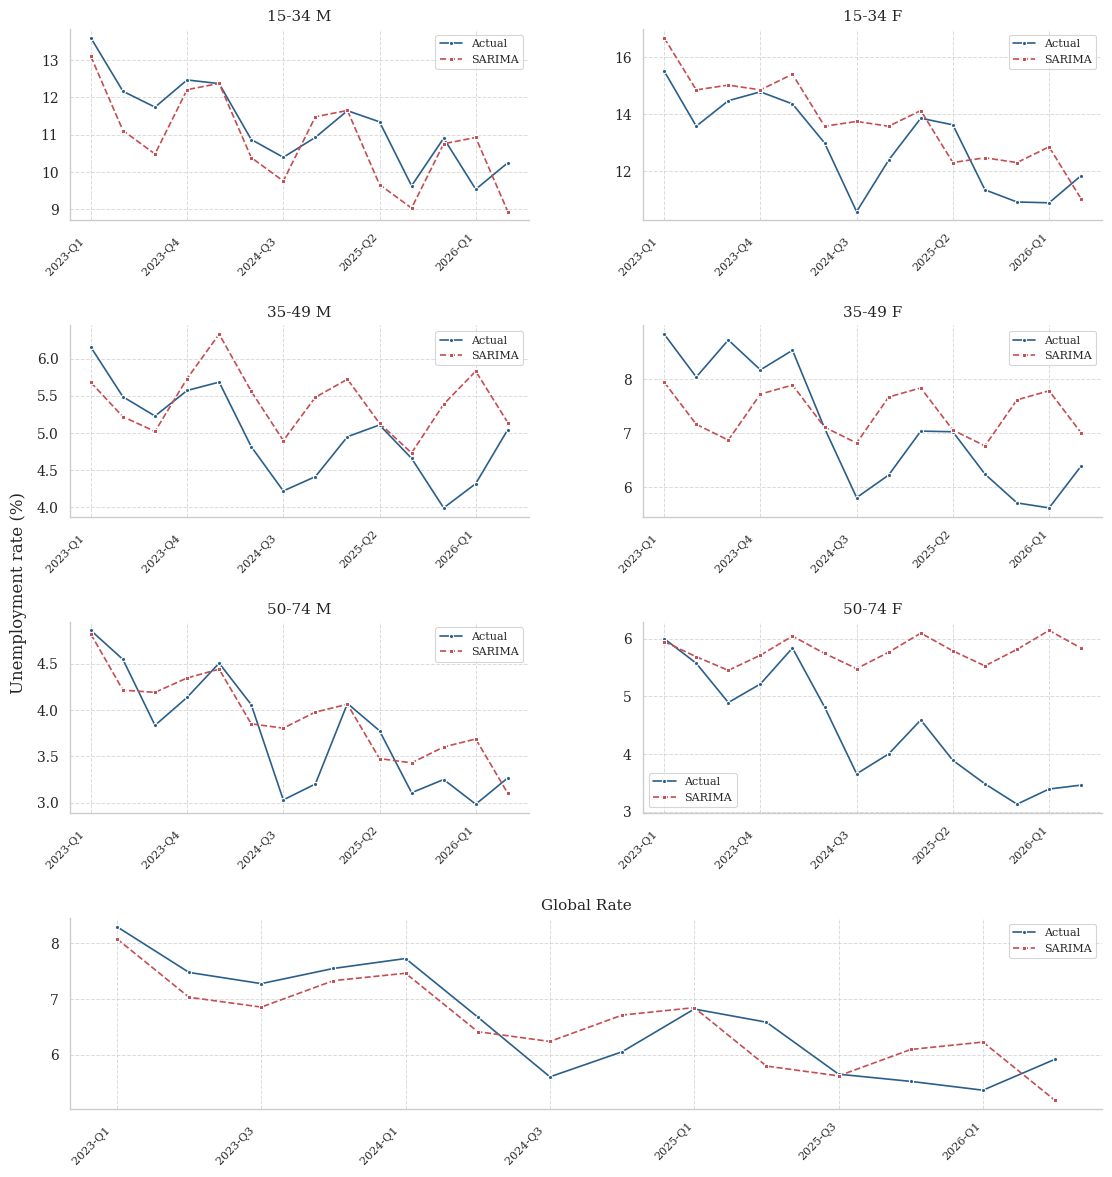

In [ ]:
# Vamos a plotear los resultados 

series = ["15-34 M", "15-34 F", "35-49 M", "35-49 F", "50-74 M", "50-74 F", "Global_Rate"]
x = test.index

fig = plt.figure(figsize=(12, 12))
gs = fig.add_gridspec(4, 2, hspace=0.55, wspace=0.25)
axes = [fig.add_subplot(gs[i // 2, i % 2]) for i in range(6)]
axes.append(fig.add_subplot(gs[3, :]))

for i, (ax, col) in enumerate(zip(axes, series)):
    sns.lineplot(x=x, y=test[col].to_numpy(), ax=ax,
                 color="#2B5F8A", marker="o", markersize=3,
                 linewidth=1.2, label="Actual")

    sns.lineplot(x=x, y=sarima_predictions[col], ax=ax,
                 color="#C44E52", marker="s", markersize=3,
                 linewidth=1.2, linestyle="--", label="SARIMA")

    ax.set_title(col.replace("_", " "), fontsize=11)
    ax.set(xlabel="", ylabel="")
    ticks = x[::2] if i == 6 else x[::3]
    ax.set_xticks(ticks)
    ax.set_xticklabels(ticks, rotation=45, ha="right", fontsize=8)
    ax.grid(True, axis="both", linestyle="--", linewidth=0.7, alpha=0.7)
    ax.legend(fontsize=8)
    sns.despine(ax=ax)

fig.supylabel("Unemployment rate (%)", fontsize=12, x=0.07)
fig.subplots_adjust(left=0.12, right=0.98, top=0.97, bottom=0.07)

IMG = BASE / "IMG"
IMG.mkdir(parents=True, exist_ok=True)
fig.savefig(IMG / "sarima_forecast_test.pdf", bbox_inches="tight")
plt.show()
#\caption{Forecasting performance of the selected SARIMA models on the test set, after re-estimation using the combined training and validation sets.}

In [ ]:
# Calcular los IC en el test set
rng = np.random.default_rng(42)
B = 2000
block_size = 4
ci_results = []

for col in sarima_best_params:
    real = test[col].to_numpy()
    pred = np.asarray(sarima_predictions[col])
    n = len(real)

    if n < block_size:
        raise ValueError(f"{col}: test too short for blocks of {block_size}")

    metrics = {"MSE": [], "RMSE": [], "MAE": [], "MAPE": []}

    for _ in range(B):
        starts = rng.integers(0, n-block_size+1, size=int(np.ceil(n/block_size)))
        idx = np.concatenate([np.arange(s,s+block_size) for s in starts])[:n]

        y_b = real[idx]
        p_b = pred[idx]
        errors = y_b-p_b

        mse_b = np.mean(errors**2)
        metrics["MSE"].append(mse_b)
        metrics["RMSE"].append(np.sqrt(mse_b))
        metrics["MAE"].append(np.mean(np.abs(errors)))

        mask = y_b != 0
        metrics["MAPE"].append(
            np.mean(np.abs(errors[mask]/y_b[mask]))*100
            if mask.any() else np.nan
        )

    row = {"Serie": col}
    point_metrics = {
        "MSE": np.mean((real-pred)**2),
        "RMSE": np.sqrt(np.mean((real-pred)**2)),
        "MAE": np.mean(np.abs(real-pred)),
        "MAPE": np.mean(np.abs((real[real!=0]-pred[real!=0])/real[real!=0]))*100 if np.any(real!=0) else np.nan
    }

    for metric, values in metrics.items():
        lower = np.nanpercentile(values, 2.5)
        upper = np.nanpercentile(values, 97.5)
        row[metric] = round(point_metrics[metric], 4)
        row[f"{metric} IC 95%"] = f"[{lower:.4f}, {upper:.4f}]"

    ci_results.append(row)

sarima_ci_df = pd.DataFrame(ci_results)
(BASE/"results"/"SARIMA").mkdir(parents=True, exist_ok=True)
sarima_ci_df.to_csv(BASE/"results"/"SARIMA"/"sarima_IC_test.csv", index=False)
display(sarima_ci_df)

,Serie,MSE,MSE IC 95%,RMSE,RMSE IC 95%,MAE,MAE IC 95%,MAPE,MAPE IC 95%
0,15-34 M,0.7698,"[0.3140, 1.0255]",0.8774,"[0.5604, 1.0127]",0.7049,"[0.4323, 0.8327]",6.4644,"[3.8994, 7.7943]"
1,15-34 F,1.8337,"[0.8273, 2.9253]",1.3541,"[0.9096, 1.7104]",1.1373,"[0.7789, 1.4196]",9.3924,"[5.9030, 12.3608]"
2,35-49 M,0.5566,"[0.2201, 0.8367]",0.7461,"[0.4692, 0.9147]",0.5799,"[0.3750, 0.7476]",12.5795,"[7.3081, 16.9485]"
3,35-49 F,1.3178,"[0.6856, 1.8055]",1.1480,"[0.8280, 1.3437]",0.9473,"[0.6484, 1.1159]",14.1781,"[9.2062, 18.2282]"
4,50-74 M,0.1690,"[0.0744, 0.2838]",0.4111,"[0.2728, 0.5327]",0.3291,"[0.2427, 0.4398]",9.7622,"[6.3303, 13.5432]"
5,50-74 F,2.7401,"[0.6083, 4.5188]",1.6553,"[0.7800, 2.1257]",1.3711,"[0.5869, 2.0597]",36.8782,"[12.7448, 57.6642]"
6,Global_Rate,0.2642,"[0.1303, 0.3529]",0.5140,"[0.3610, 0.5940]",0.4392,"[0.3253, 0.5083]",7.0559,"[4.6410, 8.5823]"
